
## Objective
Develop a machine-learning-based analytics solution for an e-commerce company using the **UCI Online Retail Dataset**.

### Tasks
1. Preprocess transaction data.
2. Engineer customer-level RFM and purchasing features.
3. Perform K-Means clustering and select the number of clusters using the Elbow Method.
4. Compare with Hierarchical Clustering using a dendrogram.
5. Evaluate clustering using Silhouette Score.
6. Apply PCA and visualize customer segments in 2D.
7. Profile and interpret customer clusters.
8. Identify a high-value customer segment.
9. Build Random Forest and SVM models to predict high-value customers.
10. Compare Accuracy, Precision, Recall, F1 and ROC-AUC.
11. Analyze feature importance.
12. Create an interactive 3D Plotly visualization.
13. Provide segment-wise marketing recommendations.

**Dataset:** UCI Machine Learning Repository — Online Retail Dataset.

In [1]:
!pip -q install openpyxl scikit-learn scipy seaborn plotly

In [2]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from scipy.cluster.hierarchy import linkage, dendrogram

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix,
    classification_report
)
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 1. Download and Load the UCI Online Retail Dataset

In [4]:
import requests
import zipfile
import io
import os

url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    print("Files in ZIP:")
    print(z.namelist())

    # Extract the Excel file
    excel_file = [
        f for f in z.namelist()
        if f.lower().endswith(".xlsx")
    ][0]

    z.extract(excel_file, "/content")

file_path = os.path.join("/content", excel_file)

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Files in ZIP:
['Online Retail.xlsx']
Dataset loaded successfully!
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum())

print("\nDescriptive statistics:")
display(df.describe(include="all").T.head(20))

Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

Missing values:


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



Descriptive statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data Preprocessing

In [6]:
data = df.copy()

# Standardize column names
data.columns = [
    "InvoiceNo", "StockCode", "Description",
    "Quantity", "InvoiceDate", "UnitPrice",
    "CustomerID", "Country"
]

# Remove rows without CustomerID
data = data.dropna(subset=["CustomerID"])

# Remove cancelled invoices
data = data[~data["InvoiceNo"].astype(str).str.startswith("C")]

# Remove invalid quantities and prices
data = data[data["Quantity"] > 0]
data = data[data["UnitPrice"] > 0]

# Convert types
data["CustomerID"] = data["CustomerID"].astype(int)
data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])

# Transaction revenue
data["Revenue"] = data["Quantity"] * data["UnitPrice"]

print("Original rows:", len(df))
print("Rows after preprocessing:", len(data))
print("Unique customers:", data["CustomerID"].nunique())
print("Unique invoices:", data["InvoiceNo"].nunique())

display(data.head())

Original rows: 541909
Rows after preprocessing: 397884
Unique customers: 4338
Unique invoices: 18532


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## 3. Exploratory Data Analysis

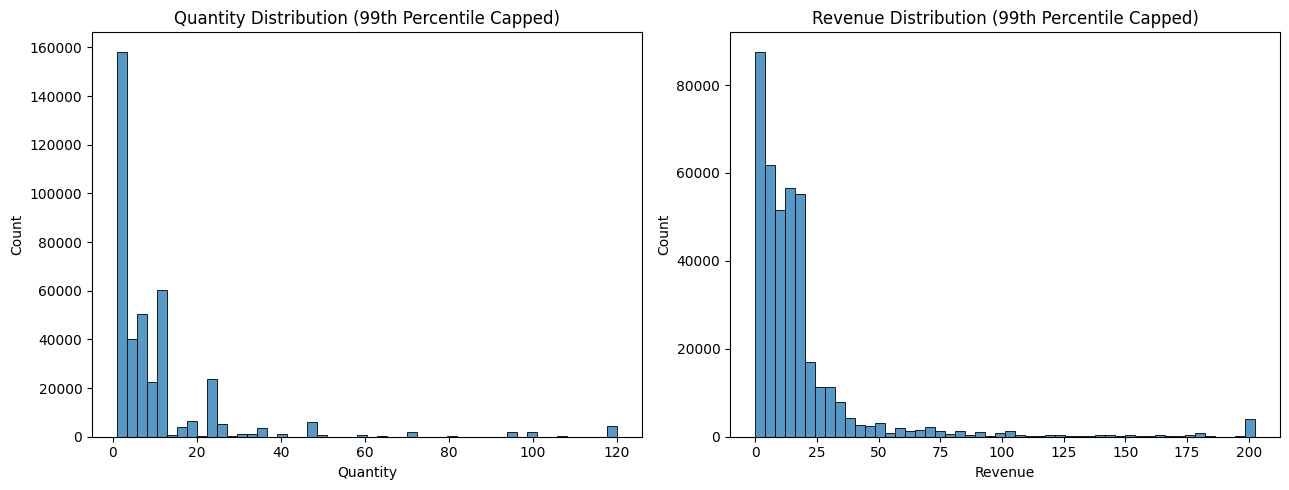

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(data["Quantity"].clip(upper=data["Quantity"].quantile(0.99)),
             bins=50, ax=axes[0])
axes[0].set_title("Quantity Distribution (99th Percentile Capped)")

sns.histplot(data["Revenue"].clip(upper=data["Revenue"].quantile(0.99)),
             bins=50, ax=axes[1])
axes[1].set_title("Revenue Distribution (99th Percentile Capped)")

plt.tight_layout()
plt.show()

## 4. Customer-Level Feature Engineering — RFM and Additional Features

In [8]:
reference_date = data["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = data.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
    QuantityPurchased=("Quantity", "sum"),
    TotalTransactions=("InvoiceNo", "count"),
    AverageTransactionValue=("Revenue", "mean")
).reset_index()

rfm["Recency"] = (
    reference_date - rfm["LastPurchase"]
).dt.days

rfm["PurchaseFrequency"] = (
    rfm["Frequency"] / rfm["Recency"].replace(0, 1)
)

rfm = rfm.drop(columns=["LastPurchase"])

print("Customer-level dataset shape:", rfm.shape)
display(rfm.head())

Customer-level dataset shape: (4338, 8)


,CustomerID,Frequency,Monetary,QuantityPurchased,TotalTransactions,AverageTransactionValue,Recency,PurchaseFrequency
0,12346,1,77183.60,74215,1,77183.600000,326,0.003067
1,12347,7,4310.00,2458,182,23.681319,2,3.500000
2,12348,4,1797.24,2341,31,57.975484,75,0.053333
3,12349,1,1757.55,631,73,24.076027,19,0.052632
4,12350,1,334.40,197,17,19.670588,310,0.003226


## 5. Treat Extreme Outliers

In [9]:
feature_cols = [
    "Recency",
    "Frequency",
    "Monetary",
    "QuantityPurchased",
    "TotalTransactions",
    "AverageTransactionValue",
    "PurchaseFrequency"
]

# Winsorize each numeric feature at 1st and 99th percentiles
rfm_model = rfm.copy()

for col in feature_cols:
    low = rfm_model[col].quantile(0.01)
    high = rfm_model[col].quantile(0.99)
    rfm_model[col] = rfm_model[col].clip(low, high)

print("Features used:")
print(feature_cols)
display(rfm_model[feature_cols].describe().T)

Features used:
['Recency', 'Frequency', 'Monetary', 'QuantityPurchased', 'TotalTransactions', 'AverageTransactionValue', 'PurchaseFrequency']


,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,92.500692,99.914624,1.000000,18.000000,51.000000,142.000000,369.000000
Frequency,4338.0,4.008760,4.863497,1.000000,1.000000,2.000000,5.000000,30.000000
Monetary,4338.0,1598.762482,2797.725260,52.200000,307.415000,674.485000,1661.740000,19880.995700
QuantityPurchased,4338.0,925.967616,1587.963479,12.000000,160.000000,379.000000,992.750000,11046.580000
TotalTransactions,4338.0,83.183771,113.889313,1.000000,17.000000,41.000000,100.000000,668.300000
AverageTransactionValue,4338.0,29.565517,49.181532,3.128482,12.365367,17.723119,24.858417,366.753447
PurchaseFrequency,4338.0,0.568888,1.824637,0.002710,0.012121,0.045455,0.227273,13.000000


## 6. Log Transform and Standardization

In [10]:
X_raw = rfm_model[feature_cols].copy()

# Log transform skewed positive variables
X_log = np.log1p(X_raw)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=feature_cols,
    index=rfm_model.index
)

print("Scaled feature matrix:", X_scaled.shape)
display(X_scaled_df.head())

Scaled feature matrix: (4338, 7)


,Recency,Frequency,Monetary,QuantityPurchased,TotalTransactions,AverageTransactionValue,PurchaseFrequency
0,1.462228,-0.974100,2.726005,2.526970,-2.460375,3.626890,-0.494874
1,-2.038890,1.110952,1.466120,1.385192,1.196892,0.286786,2.583011
2,0.373218,0.404045,0.745485,1.348145,-0.215172,1.363827,-0.394609
3,-0.623084,-0.974100,0.727090,0.352720,0.463695,0.306404,-0.395976
4,1.424788,-0.974100,-0.638518,-0.529284,-0.681094,0.067521,-0.494550


## 7. Elbow Method for K-Means

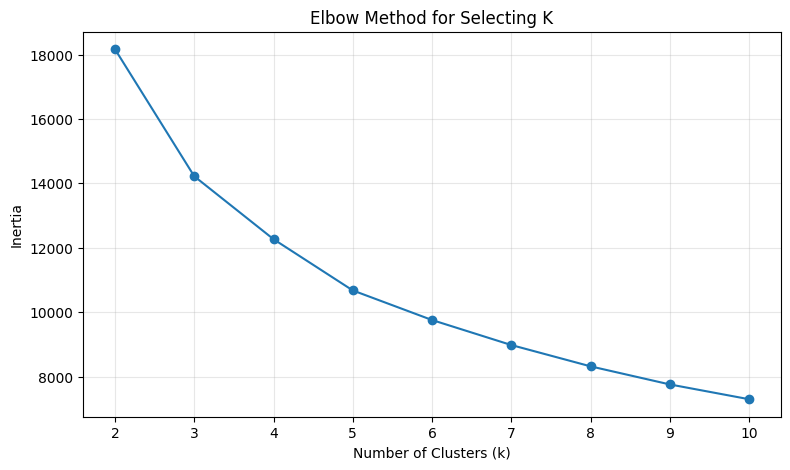

In [11]:
inertias = []
k_values = range(2, 11)

for k in k_values:
    km = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Selecting K")
plt.grid(alpha=0.3)
plt.show()

### Selecting K

The elbow plot should be inspected to identify the point where adding additional clusters produces diminishing reduction in inertia.

For this notebook, the default is **4 clusters**. If your elbow plot clearly indicates another value, change `OPTIMAL_K` before continuing.

In [12]:
OPTIMAL_K = 4

kmeans = KMeans(
    n_clusters=OPTIMAL_K,
    random_state=RANDOM_STATE,
    n_init=10
)

rfm_model["KMeansCluster"] = kmeans.fit_predict(X_scaled)

silhouette_kmeans = silhouette_score(
    X_scaled,
    rfm_model["KMeansCluster"]
)

print("K-Means Silhouette Score:", round(silhouette_kmeans, 4))
print("\nCluster counts:")
print(rfm_model["KMeansCluster"].value_counts().sort_index())

K-Means Silhouette Score: 0.2315

Cluster counts:
KMeansCluster
0     333
1    1252
2    1613
3    1140
Name: count, dtype: int64


## 8. Hierarchical Clustering and Dendrogram

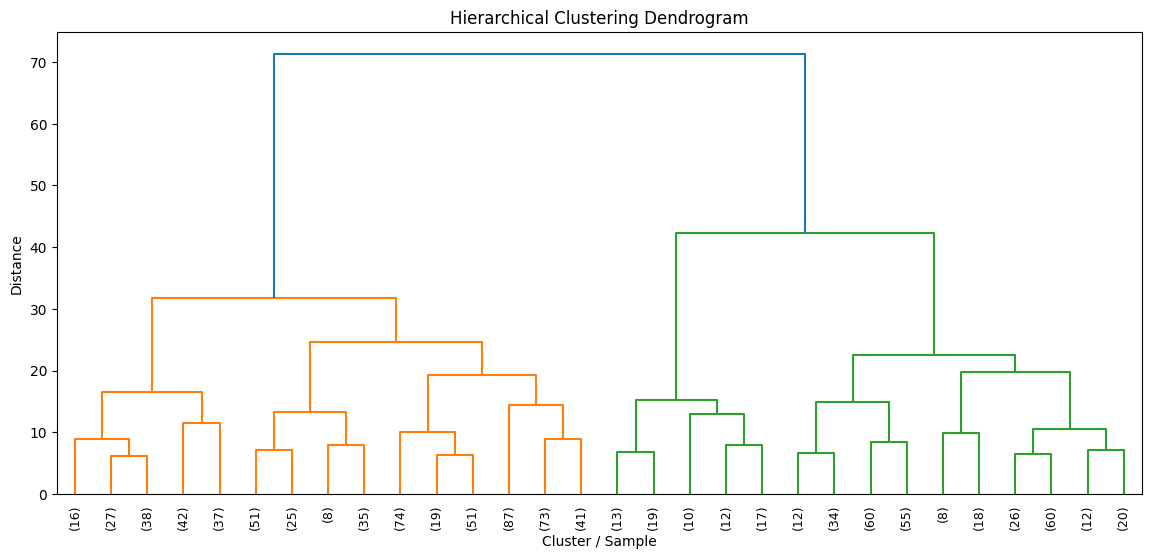

In [13]:
# Sample for a readable dendrogram
sample_size = min(1000, len(X_scaled))
sample_indices = np.random.RandomState(RANDOM_STATE).choice(
    len(X_scaled), sample_size, replace=False
)

Z = linkage(
    X_scaled[sample_indices],
    method="ward"
)

plt.figure(figsize=(14, 6))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=9
)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster / Sample")
plt.ylabel("Distance")
plt.show()

In [14]:
hierarchical = AgglomerativeClustering(
    n_clusters=OPTIMAL_K,
    linkage="ward"
)

hier_labels = hierarchical.fit_predict(X_scaled)

hier_silhouette = silhouette_score(
    X_scaled,
    hier_labels
)

rfm_model["HierarchicalCluster"] = hier_labels

print("Hierarchical Clustering Silhouette Score:",
      round(hier_silhouette, 4))

Hierarchical Clustering Silhouette Score: 0.1954


## 9. Compare Clustering Quality

In [15]:
cluster_comparison = pd.DataFrame({
    "Method": ["K-Means", "Hierarchical"],
    "Silhouette Score": [
        silhouette_kmeans,
        hier_silhouette
    ]
})

display(cluster_comparison.round(4))

,Method,Silhouette Score
0,K-Means,0.2315
1,Hierarchical,0.1954


## 10. PCA — 2D Visualization of Customer Segments

In [16]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

rfm_model["PCA1"] = X_pca[:, 0]
rfm_model["PCA2"] = X_pca[:, 1]

print("Explained variance:")
print("PC1:", round(pca.explained_variance_ratio_[0], 4))
print("PC2:", round(pca.explained_variance_ratio_[1], 4))
print("Total:", round(pca.explained_variance_ratio_.sum(), 4))

Explained variance:
PC1: 0.6133
PC2: 0.1817
Total: 0.795


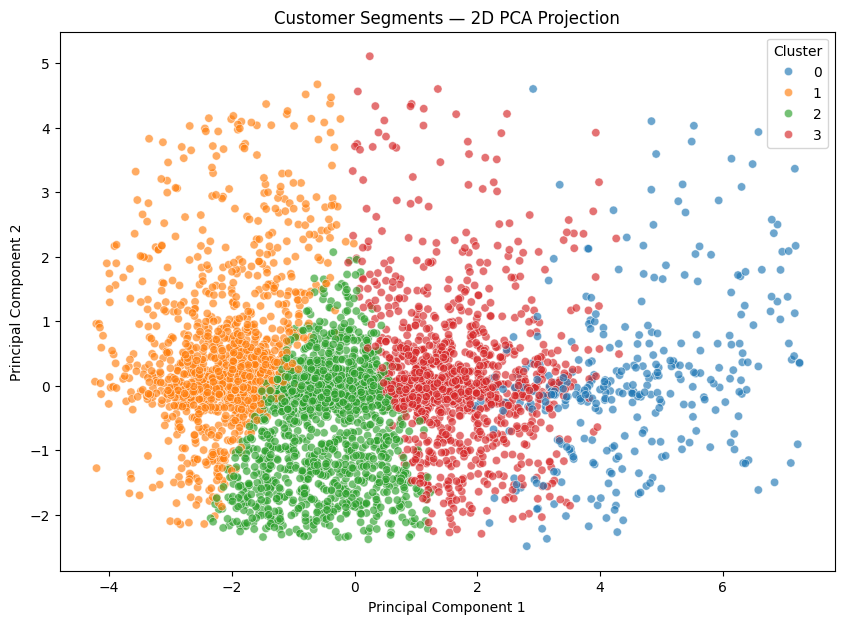

In [17]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=rfm_model,
    x="PCA1",
    y="PCA2",
    hue="KMeansCluster",
    palette="tab10",
    alpha=0.65
)

plt.title("Customer Segments — 2D PCA Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

## 11. Customer Cluster Profiling

In [18]:
profile_cols = [
    "Recency",
    "Frequency",
    "Monetary",
    "QuantityPurchased",
    "TotalTransactions",
    "AverageTransactionValue",
    "PurchaseFrequency"
]

cluster_profile = rfm_model.groupby("KMeansCluster")[profile_cols].mean()
cluster_counts = rfm_model["KMeansCluster"].value_counts().sort_index()

cluster_profile["Customers"] = cluster_counts
cluster_profile["Customer %"] = (
    cluster_profile["Customers"] / len(rfm_model) * 100
)

display(cluster_profile.round(2))

,Recency,Frequency,Monetary,QuantityPurchased,TotalTransactions,AverageTransactionValue,PurchaseFrequency,Customers,Customer %
KMeansCluster,,,,,,,,,
0,4.24,15.61,6925.55,3888.42,296.15,38.53,5.54,333,7.68
1,172.66,1.30,319.80,165.15,11.23,42.91,0.02,1252,28.86
2,86.82,2.18,629.40,380.81,53.29,15.00,0.09,1613,37.18
3,38.29,6.17,2818.96,1667.52,142.30,32.91,0.39,1140,26.28


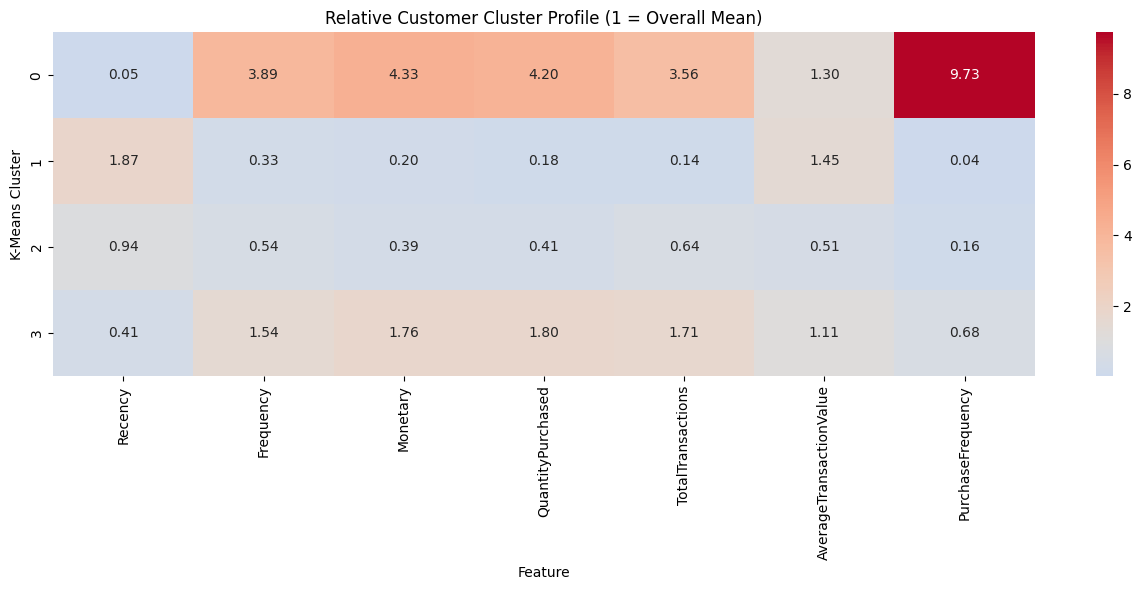

In [19]:
# Relative profile: each cluster's value divided by overall mean
relative_profile = (
    cluster_profile[profile_cols]
    / rfm_model[profile_cols].mean()
)

plt.figure(figsize=(13, 6))
sns.heatmap(
    relative_profile,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=1
)
plt.title("Relative Customer Cluster Profile (1 = Overall Mean)")
plt.xlabel("Feature")
plt.ylabel("K-Means Cluster")
plt.tight_layout()
plt.show()

## 12. Identify the High-Value Customer Segment

In [20]:
# High-value segment is defined using Monetary Value and Frequency.
# The cluster with the highest combined standardized Monetary + Frequency
# profile is selected as the high-value segment.

cluster_scores = cluster_profile[["Monetary", "Frequency"]].copy()

cluster_scores["Monetary_z"] = (
    cluster_scores["Monetary"] - cluster_scores["Monetary"].mean()
) / cluster_scores["Monetary"].std()

cluster_scores["Frequency_z"] = (
    cluster_scores["Frequency"] - cluster_scores["Frequency"].mean()
) / cluster_scores["Frequency"].std()

cluster_scores["HighValueScore"] = (
    cluster_scores["Monetary_z"] +
    cluster_scores["Frequency_z"]
)

high_value_cluster = cluster_scores["HighValueScore"].idxmax()

print("Identified high-value cluster:", high_value_cluster)
display(cluster_scores.sort_values("HighValueScore", ascending=False).round(3))

rfm_model["HighValue"] = (
    rfm_model["KMeansCluster"] == high_value_cluster
).astype(int)

print("\nHigh-value customers:", rfm_model["HighValue"].sum())
print("Other customers:", (rfm_model["HighValue"] == 0).sum())

Identified high-value cluster: 0


,Monetary,Frequency,Monetary_z,Frequency_z,HighValueScore
KMeansCluster,,,,,
0,6925.550,15.613,1.396,1.419,2.816
3,2818.955,6.175,0.048,-0.022,0.026
2,629.404,2.182,-0.671,-0.632,-1.303
1,319.797,1.304,-0.773,-0.766,-1.539



High-value customers: 333
Other customers: 4005


## 13. Prepare Data for Supervised Learning

In [21]:
prediction_features = feature_cols

X = rfm_model[prediction_features].copy()
y = rfm_model["HighValue"]

# Use the same preprocessing approach as clustering
X = np.log1p(X)
X = StandardScaler().fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nClass distribution:")
print(y.value_counts())

Training samples: 3470
Testing samples: 868

Class distribution:
HighValue
0    4005
1     333
Name: count, dtype: int64


## 14. Random Forest Classifier

In [22]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=5,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)

start = time.time()
rf_model.fit(X_train, y_train)
rf_train_time = time.time() - start

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

rf_metrics = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred, zero_division=0),
    "Recall": recall_score(y_test, rf_pred, zero_division=0),
    "F1-Score": f1_score(y_test, rf_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, rf_prob),
    "Training Time (sec)": rf_train_time
}

print(rf_metrics)

{'Model': 'Random Forest', 'Accuracy': 0.9953917050691244, 'Precision': 0.9701492537313433, 'Recall': 0.9701492537313433, 'F1-Score': 0.9701492537313433, 'ROC-AUC': np.float64(0.999832299178266), 'Training Time (sec)': 0.7478535175323486}


## 15. SVM Classifier

In [23]:
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    probability=True,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

start = time.time()
svm_model.fit(X_train, y_train)
svm_train_time = time.time() - start

svm_pred = svm_model.predict(X_test)
svm_prob = svm_model.predict_proba(X_test)[:, 1]

svm_metrics = {
    "Model": "SVM",
    "Accuracy": accuracy_score(y_test, svm_pred),
    "Precision": precision_score(y_test, svm_pred, zero_division=0),
    "Recall": recall_score(y_test, svm_pred, zero_division=0),
    "F1-Score": f1_score(y_test, svm_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, svm_prob),
    "Training Time (sec)": svm_train_time
}

print(svm_metrics)

{'Model': 'SVM', 'Accuracy': 0.9896313364055299, 'Precision': 0.881578947368421, 'Recall': 1.0, 'F1-Score': 0.9370629370629371, 'ROC-AUC': np.float64(0.9999068328768144), 'Training Time (sec)': 0.08168721199035645}


## 16. Supervised Model Comparison

In [24]:
model_comparison = pd.DataFrame([
    rf_metrics,
    svm_metrics
]).set_index("Model")

display(model_comparison.round(4))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Training Time (sec)
Model,,,,,,
Random Forest,0.9954,0.9701,0.9701,0.9701,0.9998,0.7479
SVM,0.9896,0.8816,1.0000,0.9371,0.9999,0.0817


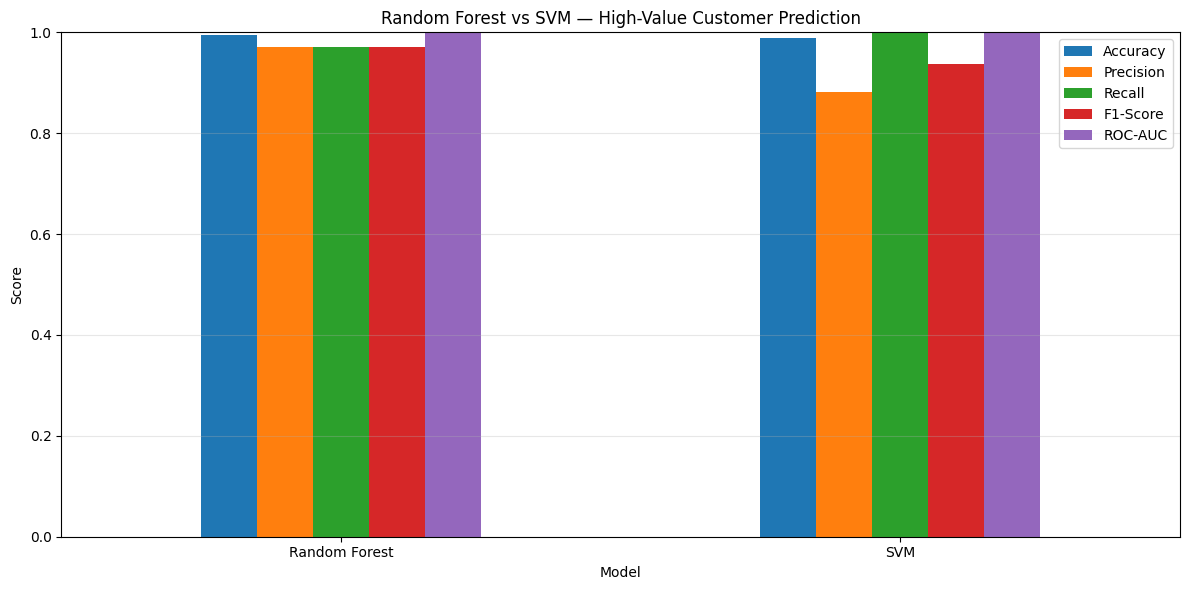

In [25]:
model_comparison[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Random Forest vs SVM — High-Value Customer Prediction")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 17. Confusion Matrices

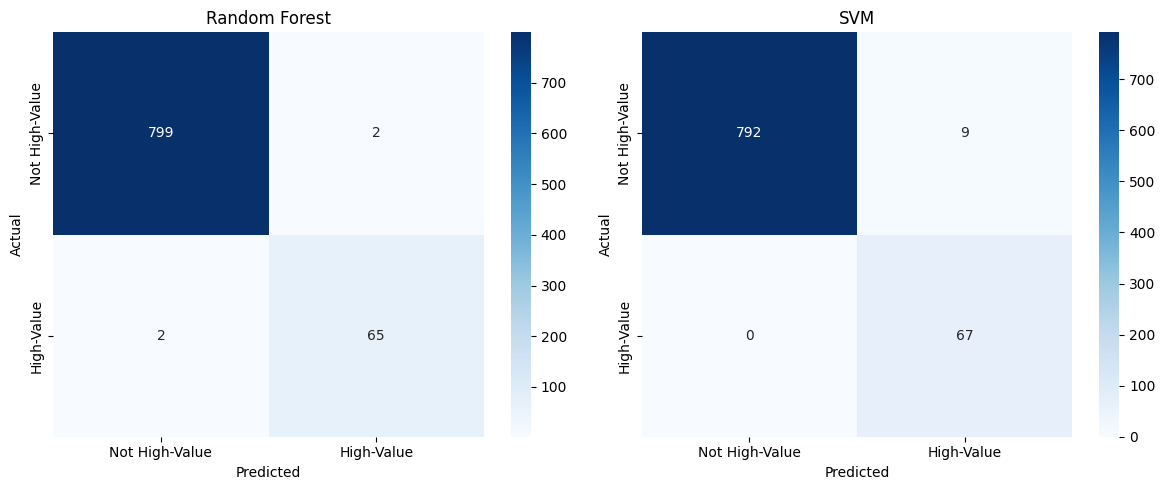

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf = confusion_matrix(y_test, rf_pred)
cm_svm = confusion_matrix(y_test, svm_pred)

sns.heatmap(
    cm_rf, annot=True, fmt="d", cmap="Blues",
    ax=axes[0],
    xticklabels=["Not High-Value", "High-Value"],
    yticklabels=["Not High-Value", "High-Value"]
)
axes[0].set_title("Random Forest")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cm_svm, annot=True, fmt="d", cmap="Blues",
    ax=axes[1],
    xticklabels=["Not High-Value", "High-Value"],
    yticklabels=["Not High-Value", "High-Value"]
)
axes[1].set_title("SVM")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

## 18. Classification Reports

In [27]:
print("RANDOM FOREST")
print(classification_report(
    y_test, rf_pred,
    target_names=["Not High-Value", "High-Value"],
    digits=4,
    zero_division=0
))

print("\nSVM")
print(classification_report(
    y_test, svm_pred,
    target_names=["Not High-Value", "High-Value"],
    digits=4,
    zero_division=0
))

RANDOM FOREST
                precision    recall  f1-score   support

Not High-Value     0.9975    0.9975    0.9975       801
    High-Value     0.9701    0.9701    0.9701        67

      accuracy                         0.9954       868
     macro avg     0.9838    0.9838    0.9838       868
  weighted avg     0.9954    0.9954    0.9954       868


SVM
                precision    recall  f1-score   support

Not High-Value     1.0000    0.9888    0.9944       801
    High-Value     0.8816    1.0000    0.9371        67

      accuracy                         0.9896       868
     macro avg     0.9408    0.9944    0.9657       868
  weighted avg     0.9909    0.9896    0.9899       868



## 19. Random Forest Feature Importance

,Importance
PurchaseFrequency,0.3998
Recency,0.2549
Frequency,0.1439
Monetary,0.0957
QuantityPurchased,0.0584
TotalTransactions,0.0432
AverageTransactionValue,0.0041


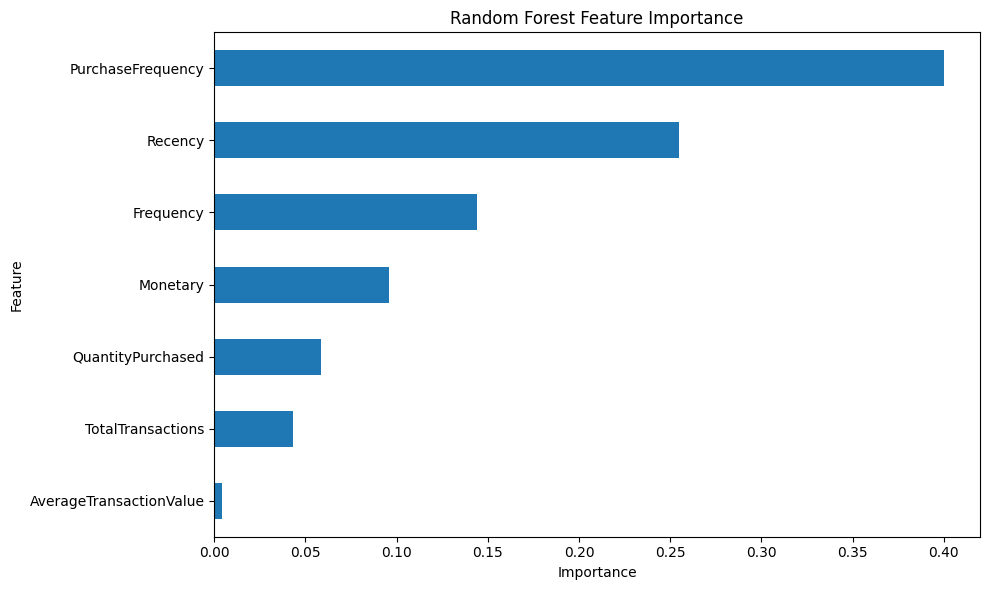

In [28]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=prediction_features
).sort_values(ascending=False)

display(importance.to_frame("Importance").round(4))

plt.figure(figsize=(10, 6))
importance.sort_values().plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 20. Interactive 3D Customer Cluster Visualization

In [29]:
pca3 = PCA(n_components=3, random_state=RANDOM_STATE)
X_pca3 = pca3.fit_transform(X_scaled)

plot3d = pd.DataFrame({
    "PCA1": X_pca3[:, 0],
    "PCA2": X_pca3[:, 1],
    "PCA3": X_pca3[:, 2],
    "Cluster": rfm_model["KMeansCluster"].astype(str),
    "Monetary": rfm_model["Monetary"],
    "Frequency": rfm_model["Frequency"],
    "Recency": rfm_model["Recency"]
})

fig = px.scatter_3d(
    plot3d,
    x="PCA1",
    y="PCA2",
    z="PCA3",
    color="Cluster",
    hover_data=["Monetary", "Frequency", "Recency"],
    title="Interactive 3D Customer Segmentation — PCA"
)

fig.show()

## 21. Segment-Wise Marketing Recommendations

In [30]:
def segment_label(row, overall):
    r = row["Recency"] < overall["Recency"]
    f = row["Frequency"] > overall["Frequency"]
    m = row["Monetary"] > overall["Monetary"]

    if f and m and r:
        return "High-Value / Loyal"
    elif m and not r:
        return "High-Spend / At-Risk"
    elif f and not m:
        return "Frequent / Lower-Value"
    elif not r and not f and not m:
        return "Low-Engagement"
    else:
        return "Potential / Growing"

overall = rfm_model[profile_cols].mean()

marketing = cluster_profile.copy()
marketing["Segment Type"] = [
    segment_label(row, overall)
    for _, row in marketing.iterrows()
]

recommendations = {
    "High-Value / Loyal":
        "VIP rewards, loyalty benefits, early product access and personalized offers.",
    "High-Spend / At-Risk":
        "Win-back campaigns, personalized discounts and targeted re-engagement.",
    "Frequent / Lower-Value":
        "Cross-selling, bundles and minimum-spend offers to increase basket value.",
    "Low-Engagement":
        "Reactivation emails, introductory offers and low-cost engagement campaigns.",
    "Potential / Growing":
        "Personalized recommendations and incentives to increase purchase frequency."
}

marketing["Marketing Recommendation"] = [
    recommendations.get(
        x,
        "Use targeted offers based on purchasing behavior."
    )
    for x in marketing["Segment Type"]
]

display(
    marketing[
        ["Customers", "Customer %", "Segment Type",
         "Marketing Recommendation"]
    ].round(2)
)

,Customers,Customer %,Segment Type,Marketing Recommendation
KMeansCluster,,,,
0,333,7.68,High-Value / Loyal,"VIP rewards, loyalty benefits, early product a..."
1,1252,28.86,Low-Engagement,"Reactivation emails, introductory offers and l..."
2,1613,37.18,Potential / Growing,Personalized recommendations and incentives to...
3,1140,26.28,High-Value / Loyal,"VIP rewards, loyalty benefits, early product a..."


## 22. Final Summary

In [31]:
summary = {
    "Number of customers": len(rfm_model),
    "Number of K-Means clusters": OPTIMAL_K,
    "K-Means Silhouette Score": round(silhouette_kmeans, 4),
    "Hierarchical Silhouette Score": round(hier_silhouette, 4),
    "High-value cluster": int(high_value_cluster),
    "High-value customers": int(rfm_model["HighValue"].sum()),
    "Random Forest ROC-AUC": round(rf_metrics["ROC-AUC"], 4),
    "SVM ROC-AUC": round(svm_metrics["ROC-AUC"], 4)
}

for k, v in summary.items():
    print(f"{k}: {v}")

Number of customers: 4338
Number of K-Means clusters: 4
K-Means Silhouette Score: 0.2315
Hierarchical Silhouette Score: 0.1954
High-value cluster: 0
High-value customers: 333
Random Forest ROC-AUC: 0.9998
SVM ROC-AUC: 0.9999


## Conclusion

The experiment applies customer-level feature engineering, clustering, dimensionality reduction and supervised learning to the UCI Online Retail dataset. K-Means and Hierarchical Clustering identify distinct customer segments, while PCA provides a lower-dimensional visualization of those segments. A high-value segment is then used as the target for Random Forest and SVM classification. The final evaluation compares clustering quality and predictive performance using the required metrics, while feature importance and segment profiles support targeted marketing recommendations.